# DDPM Policy：条件二维轨迹生成

**Transformer-to-VLA · Chapter 04 / Generative Policies · DDPM Policy**

将之前《重要：：diffusion》里的 `dataset.py / diffusion.py / model.py / train.py / sample.py` 教学内容合并成一份按步骤执行的 Notebook。

**目标：** 输入机器人起点和目标位置 $o=[x_s,y_s,x_g,y_g]$，由 DDPM 一次生成未来 $H=16$ 个二维轨迹点，即一个 action chunk。这里的点属于**教学用轨迹表示**，还不是包含动力学约束的真实机器人控制指令。

运行环境：VS Code / Jupyter、本地 Python，依赖 `torch numpy matplotlib`，无需任何图像数据集。

## 1. 环境、随机种子和运行设备

In [1]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
H = 16
print("device:", device, "horizon:", H)

device: cuda horizon: 16


## 2. 构造条件轨迹数据集（原 `dataset.py`）

每个样本包含：

- **观测条件** $o=[x_s,y_s,x_g,y_g]\in\mathbb R^4$：二维起点与目标点。
- **干净轨迹** $A_0\in\mathbb R^{H\times 2}$：由线性插值与少量随机扰动组成。

$$
a_h=(1-r_h)s+r_hg+\eta_h,\qquad r_h=\frac{h}{H-1}.
$$

为了让起点/终点严格与条件一致，下面将两个端点的扰动置零。该数据集只包含近似直线，**不具备多模态绕障能力**；后续可增加障碍物与多条不同路径。

obs: torch.Size([4, 4]) trajectory: torch.Size([4, 16, 2])


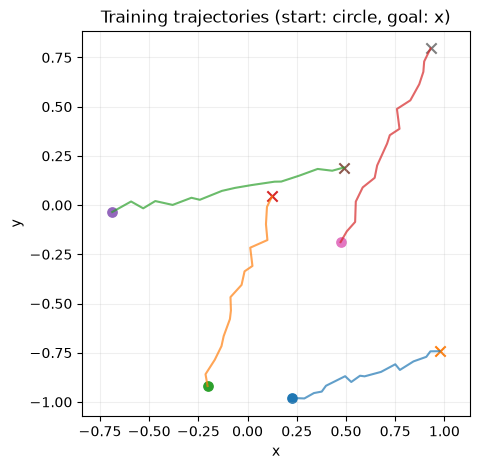

In [2]:
def generate_data(batch_size):
    start = torch.rand(batch_size, 2, device=device) * 2 - 1
    goal = torch.rand(batch_size, 2, device=device) * 2 - 1
    obs = torch.cat([start, goal], dim=1)  # [B, 4]
    ratio = torch.linspace(0, 1, H, device=device)
    trajectory = (start[:, None, :] * (1-ratio[None, :, None])
                  + goal[:, None, :] * ratio[None, :, None])
    noise = 0.02 * torch.randn_like(trajectory)
    noise[:, 0] = 0
    noise[:, -1] = 0
    trajectory = trajectory + noise
    return obs, trajectory

obs, trajectories = generate_data(4)
print("obs:", obs.shape, "trajectory:", trajectories.shape)
assert obs.shape == (4, 4) and trajectories.shape == (4, H, 2)
assert torch.allclose(trajectories[:,0,:], obs[:,:2])
assert torch.allclose(trajectories[:,-1,:], obs[:,2:])

fig, ax = plt.subplots(figsize=(5, 5))
for i in range(4):
    traj = trajectories[i].cpu().numpy()
    ax.plot(traj[:,0], traj[:,1], alpha=.7)
    ax.scatter(traj[0,0], traj[0,1], marker="o", s=45)
    ax.scatter(traj[-1,0], traj[-1,1], marker="x", s=55)
ax.set(xlabel="x", ylabel="y", title="Training trajectories (start: circle, goal: x)")
ax.axis("equal"); ax.grid(alpha=.2); plt.show()

## 3. DDPM 噪声调度与前向加噪（原 `diffusion.py`）

扩散对象从二维点 $x\in\mathbb R^2$ 变成整段轨迹 $A_0\in\mathbb R^{H\times 2}$。对于随机离散时间步 $t$：

$$
A_t=\sqrt{\bar\alpha_t}A_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad \epsilon\sim\mathcal N(0,I).
$$

`T=100` 与线性 `beta` 作为入门配置。注意扩散时间步 $t$ **不是轨迹中的第 $h$ 个动作步**。

**索引约定**：公式用 $t=1,\ldots,T$ 表示加噪步，$A_0$ 是干净轨迹；代码 `t=0,...,T-1` 对应公式的第 `t+1` 步。

**末端分布检查**：当前短链配置下，$\bar\alpha_T\approx 0.364$，末端仍含原始信号，不能视为已经完全变成标准高斯。采样用 $\mathcal N(0,I)$ 初始化是一项近似，会带来末端分布不匹配。保留此配置用于观察机制；使用相同线性端点并取 `T=1000` 时，$\bar\alpha_T\approx4.04\times10^{-5}$，初始先验更接近前向末端。修改 `T` 后需从噪声调度开始重新运行、训练并比较生成结果。参见 [DDPM 原论文](https://arxiv.org/abs/2006.11239)。


Terminal alpha_bar: 0.363563


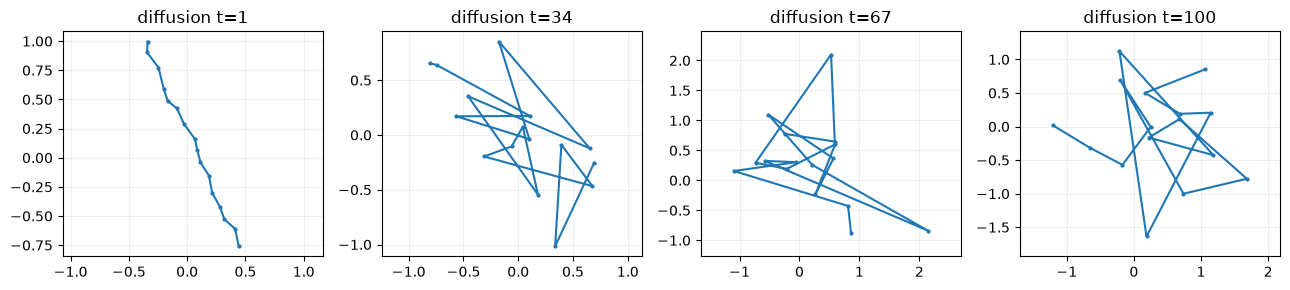

In [3]:
T = 100
beta = torch.linspace(1e-4, 0.02, T, device=device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)
print(f"Terminal alpha_bar: {alpha_bar[-1].item():.6f}")
alpha_bar_prev = torch.cat([torch.ones(1, device=device), alpha_bar[:-1]])
posterior_variance = beta * (1 - alpha_bar_prev) / (1 - alpha_bar)
posterior_variance[0] = 0.0

def q_sample(clean_actions, t, noise=None):
    if noise is None:
        noise = torch.randn_like(clean_actions)
    a = alpha_bar[t].view(-1, 1, 1)
    noisy_actions = a.sqrt() * clean_actions + (1 - a).sqrt() * noise
    return noisy_actions, noise

example_obs, clean = generate_data(1)
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, time_index in zip(axes, torch.linspace(0, T - 1, 4).round().long().tolist()):
    noisy, _ = q_sample(clean, torch.tensor([time_index], device=device))
    q = noisy[0].cpu().numpy()
    ax.plot(q[:,0], q[:,1], '-o', markersize=2)
    ax.set_title(f"diffusion t={time_index+1}"); ax.axis("equal"); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 4. 噪声预测模型（原 `model.py`）

模型学习 $\epsilon_\theta(A_t,t,o)$：将整段噪声轨迹展平，再拼上条件向量和时间嵌入，输出相同形状的噪声预测。为便于理解，先使用 MLP，不引入 U-Net、Transformer 或图像编码器。

In [4]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        assert dim >= 2 and dim % 2 == 0, "dim must be a positive even integer"
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / max(half-1, 1))
        angles = t.float()[:, None] * frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)

class ConditionalNoisePredictor(nn.Module):
    def __init__(self, horizon=H, hidden_dim=128, time_dim=32):
        super().__init__()
        self.horizon = horizon
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.net = nn.Sequential(
            nn.Linear(horizon * 2 + 4 + time_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, horizon * 2)
        )

    def forward(self, noisy_actions, t, obs):
        batch = noisy_actions.shape[0]
        flat = noisy_actions.reshape(batch, -1)
        features = torch.cat([flat, obs, self.time_embedding(t)], dim=1)
        return self.net(features).reshape(batch, self.horizon, 2)

model = ConditionalNoisePredictor().to(device)
obs_demo, actions_demo = generate_data(3)
noise_demo = model(actions_demo, torch.randint(T, (3,), device=device), obs_demo)
print("Predicted noise shape:", noise_demo.shape)
assert noise_demo.shape == actions_demo.shape

Predicted noise shape: torch.Size([3, 16, 2])


## 5. 训练条件 Diffusion Policy（原 `train.py`）

$$
\mathcal L(\theta)=\mathbb E_{A_0,o,t,\epsilon}\bigl[\|\epsilon_\theta(A_t,t,o)-\epsilon\|_2^2\bigr].
$$

训练阶段 $o$ 始终来自对应样本的起点和终点。历史实验采用 20,000 步；在 CPU 上可以先将 `TRAIN_STEPS` 改小确认运行，再恢复完整训练。

step  2000/20000: loss=0.071440


step  4000/20000: loss=0.065319


step  6000/20000: loss=0.049685


step  8000/20000: loss=0.060343


step 10000/20000: loss=0.041737


step 12000/20000: loss=0.036437


step 14000/20000: loss=0.044254


step 16000/20000: loss=0.042226


step 18000/20000: loss=0.050082


step 20000/20000: loss=0.054911


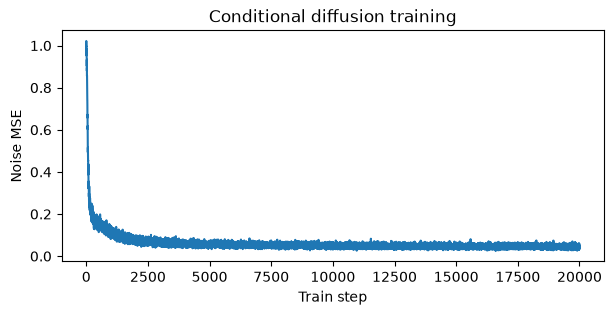

In [5]:
TRAIN_STEPS = 20_000
BATCH_SIZE = 256
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_history = []
model.train()
for step in range(TRAIN_STEPS):
    obs, clean_actions = generate_data(BATCH_SIZE)
    t = torch.randint(0, T, (BATCH_SIZE,), device=device)
    noisy_actions, true_noise = q_sample(clean_actions, t)
    pred_noise = model(noisy_actions, t, obs)
    loss = ((pred_noise - true_noise) ** 2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (step + 1) % max(1, TRAIN_STEPS // 10) == 0:
        print(f"step {step+1:5d}/{TRAIN_STEPS}: loss={loss.item():.6f}")

plt.figure(figsize=(7, 3))
plt.plot(loss_history)
plt.xlabel("Train step"); plt.ylabel("Noise MSE"); plt.title("Conditional diffusion training")
plt.show()

## 6. 从纯噪声采样动作轨迹（原 `sample.py`）

给定观测 $o$，从 $A_T\sim\mathcal N(0,I)$ 开始，按 DDPM 反向更新：

$$
\mu_\theta(A_t,t,o)=\frac{1}{\sqrt{\alpha_t}}\left(A_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(A_t,t,o)\right),
$$

$$
A_{t-1}=\mu_\theta+\sqrt{\tilde\beta_t}\,z,\qquad z\sim\mathcal N(0,I).
$$

这里使用 posterior variance $\tilde\beta_t$；在最后一步不再增加随机噪声。

In [6]:
@torch.no_grad()
def sample_policy(obs, return_snapshots=False):
    model.eval()
    batch = obs.shape[0]
    actions = torch.randn(batch, H, 2, device=obs.device)
    snapshots = {}
    if return_snapshots:
        snapshots[T] = actions.detach().cpu().clone()
    for time_index in range(T - 1, -1, -1):
        t = torch.full((batch,), time_index, device=obs.device, dtype=torch.long)
        noise_pred = model(actions, t, obs)
        mean = (actions - beta[time_index] / (1-alpha_bar[time_index]).sqrt() * noise_pred) / alpha[time_index].sqrt()
        if time_index > 0:
            actions = mean + posterior_variance[time_index].sqrt() * torch.randn_like(actions)
        else:
            actions = mean
        if return_snapshots and time_index in {3 * T // 4, T // 2, T // 4, 0}:
            snapshots[time_index] = actions.detach().cpu().clone()
    return (actions, snapshots) if return_snapshots else actions

obs_test, _ = generate_data(4)
generated, snapshots = sample_policy(obs_test, return_snapshots=True)
print("Generated action chunk shape:", generated.shape)
assert generated.shape == (4, H, 2)

Generated action chunk shape: torch.Size([4, 16, 2])


## 7. 绘制采样轨迹，并标出起点、终点及轨迹顺序

使用从深紫到黄色的 viridis 渐变区分第 1 个到第 H 个轨迹点。横跨轨迹的线仅用于帮助观察顺序。

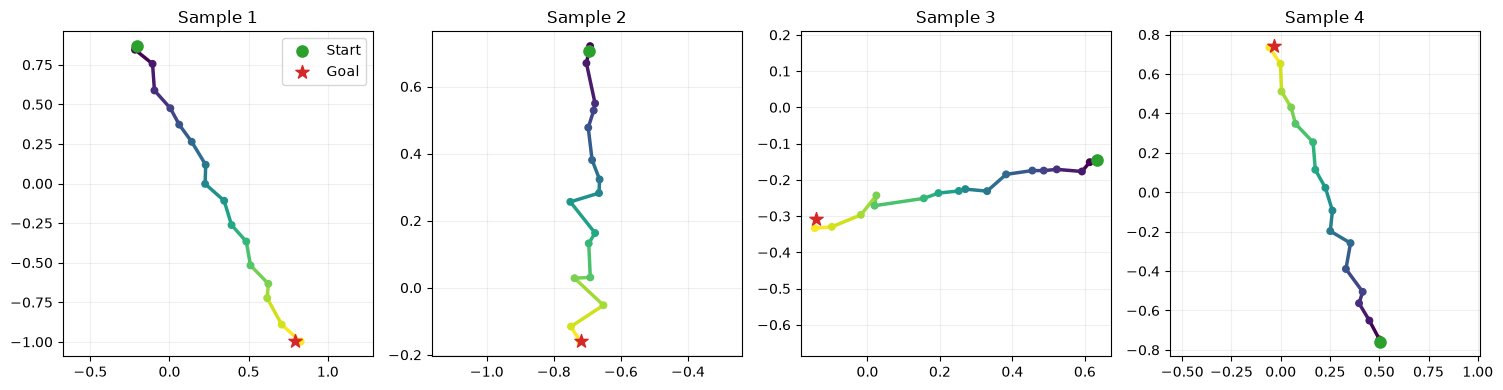

In [7]:
from matplotlib.collections import LineCollection

def draw_trajectory(ax, points, start, goal):
    points = np.asarray(points)
    segments = np.stack([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap="viridis", linewidths=2.5)
    lc.set_array(np.linspace(0, 1, len(segments)))
    ax.add_collection(lc)
    ax.scatter(points[:, 0], points[:, 1], c=np.linspace(0, 1, len(points)), cmap="viridis", s=22, zorder=3)
    ax.scatter(*start, marker="o", color="tab:green", s=65, zorder=4, label="Start")
    ax.scatter(*goal, marker="*", color="tab:red", s=100, zorder=4, label="Goal")
    ax.autoscale(); ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=.2)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i, ax in enumerate(axes):
    draw_trajectory(ax, generated[i].cpu().numpy(), obs_test[i,:2].cpu().numpy(), obs_test[i,2:].cpu().numpy())
    ax.set_title(f"Sample {i+1}")
axes[0].legend(loc="best")
plt.tight_layout(); plt.show()

## 8. 观察反向去噪过程

下面固定同一组条件、同一个生成样本，展示扩散轨迹如何逐渐由噪声变为条件化的动作序列。

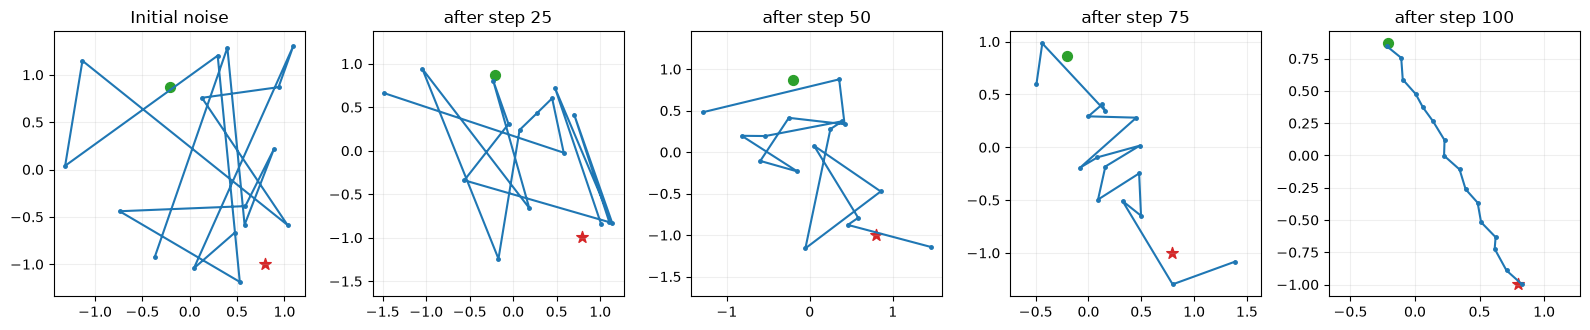

In [8]:
keys = list(snapshots)
fig, axes = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 3.4), squeeze=False)
for ax, k in zip(axes.flat, keys):
    sample = snapshots[k][0].numpy()
    ax.plot(sample[:,0], sample[:,1], '-o', markersize=2.5)
    ax.scatter(*obs_test[0,:2].cpu().numpy(), marker="o", color="tab:green", s=50)
    ax.scatter(*obs_test[0,2:].cpu().numpy(), marker="*", color="tab:red", s=75)
    ax.set_title(f"Initial noise" if k==T else f"after step {T-k}")
    ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 9. 简单定量检查：起点、终点与轨迹平滑程度

这些指标只是**教学诊断**，不能替代机器人导航任务的碰撞率、成功率等评价。

- Endpoint error：生成轨迹首末点与条件首末点的平均欧氏距离。
- Smoothness：相邻轨迹位移变化（二阶差分）的均方大小。

因为这里没有硬端点投影或动力学约束，生成的端点通常不会精确等于条件。

In [9]:
with torch.no_grad():
    endpoint_error = (torch.linalg.vector_norm(generated[:,0] - obs_test[:,:2], dim=-1).mean()
                      + torch.linalg.vector_norm(generated[:,-1] - obs_test[:,2:], dim=-1).mean()) / 2
    second_difference = generated[:,2:,:] - 2*generated[:,1:-1,:] + generated[:,:-2,:]
    smoothness = second_difference.square().mean()
print(f"Mean endpoint error: {endpoint_error.item():.4f}")
print(f"Second-difference MSE: {smoothness.item():.5f}")

Mean endpoint error: 0.0203
Second-difference MSE: 0.00393


## 10. 与真实机器人 Diffusion Policy 的关系

此处的 `observation` 仅有起点和目标，`action` 是二维坐标点序列，模型输出 $[B,H,2]$。真实机器人中往往需要：

1. 将观测替换成视觉特征、状态和语言 / 目标表征。
2. 将轨迹点替换成机器人底层控制指令（如速度、转向、关节动作）或可追踪 waypoint。
3. 执行部分动作后重新观测与生成，形成 **Receding Horizon / Action Chunk** 控制。
4. 使用障碍物信息、多模态演示和安全约束训练 / 评估策略。

**实验建议：** 调整 `H`、轨迹扰动强度、`T` 与训练轮数；观察末端误差和生成轨迹的变化。下一步可加入左右绕障两条候选轨迹，学习真正的多模态条件动作分布。